In [25]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('../insurance_lab/data/processed/insurance_clean.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,male,30.970,3,no,northwest,10600.54830
1333,18,female,31.920,0,no,northeast,2205.98080
1334,18,female,36.850,0,no,southeast,1629.83350
1335,21,female,25.800,0,no,southwest,2007.94500


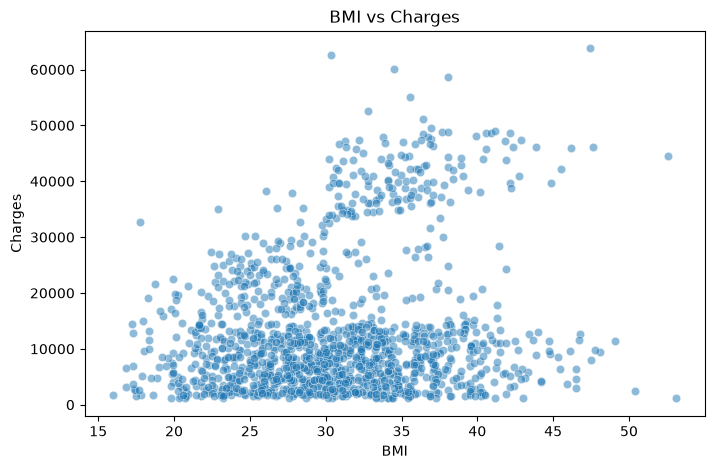

In [3]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df , x='bmi' ,y='charges' ,alpha=0.5)
plt.title('BMI vs Charges')
plt.xlabel('BMI')
plt.ylabel('Charges')
plt.show()

Text(0, 0.5, 'Charges')

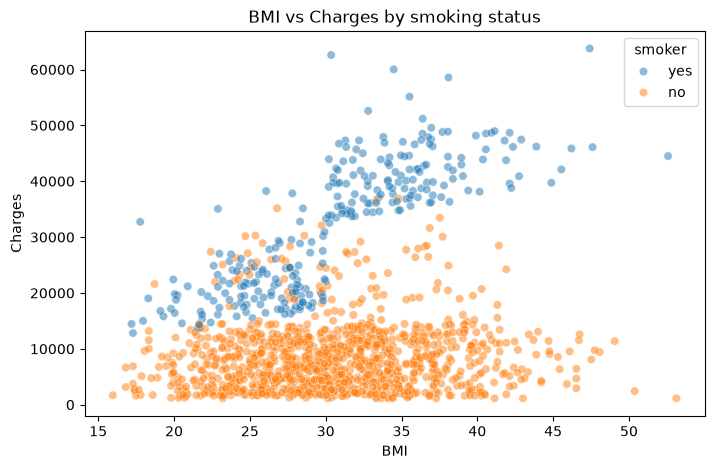

In [4]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df , x='bmi' ,y='charges',hue='smoker' ,alpha=0.5)
plt.title('BMI vs Charges by smoking status')
plt.xlabel('BMI')
plt.ylabel('Charges')

Text(42.59951475694443, 0.5, 'Charges')

<Figure size 800x500 with 0 Axes>

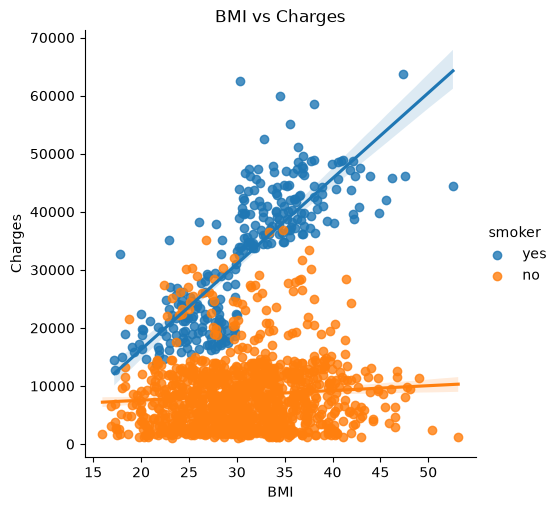

In [8]:
plt.figure(figsize=(8,5))
sns.lmplot(data=df , x='bmi' ,y='charges',hue='smoker' )
plt.title('BMI vs Charges')
plt.xlabel('BMI')
plt.ylabel('Charges')

In [21]:
overall_pearson = df['bmi'].corr(df['charges'], method='pearson')
overall_spearman = df['bmi'].corr(df['charges'], method='spearman')

df_no_smoker = df[df['smoker'] == 'no']
df_smoker = df[df['smoker'] == 'yes']

no_smoker_pearson = df_no_smoker['bmi'].corr(df_no_smoker['charges'],method='pearson')
no_smoker_spearman = df_no_smoker['bmi'].corr(df_no_smoker['charges'],method='spearman')

smoker_pearson = df_smoker['bmi'].corr(df_smoker['charges'],method='pearson')
smoker_spearman = df_smoker['bmi'].corr(df_smoker['charges'],method='spearman')

print(f'{'kind':<10} | {'pearson' :<10} | {'spearman' :<10}')
print('-'*50)
print(f'{'all':<10} | {overall_pearson:<10.4%} | {overall_spearman:<10.4%}')
print(f'{'no smoker':<10} | {no_smoker_pearson:<10.4%} | {no_smoker_spearman:<10.4%}')
print(f'{' smoker':<10} | {smoker_pearson:<10.4%} | {smoker_spearman:<10.4%}')

kind       | pearson    | spearman  
--------------------------------------------------
all        | 19.8401%   | 11.9585%  
no smoker  | 8.4077%    | 10.5373%  
 smoker    | 80.6481%   | 83.4228%  


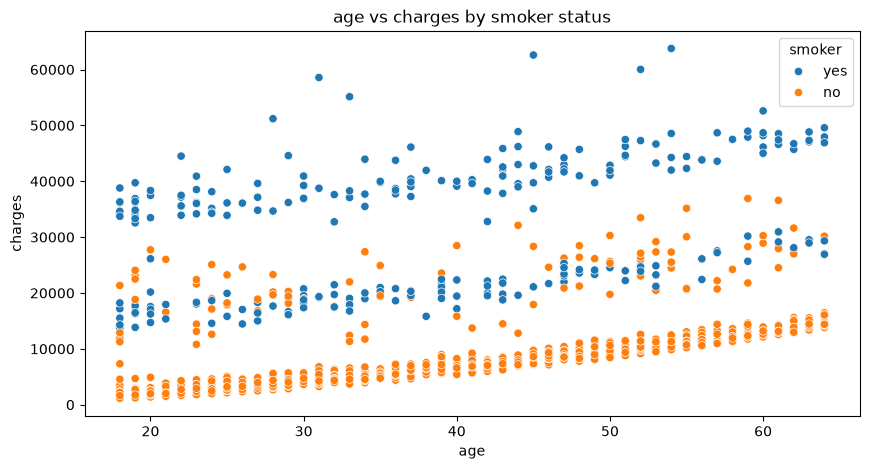

In [22]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df ,x='age',y='charges' ,hue='smoker')
plt.title('age vs charges by smoker status')
plt.xlabel('age')
plt.ylabel('charges')
plt.show()

In [23]:
overall_age_pearson = df['age'].corr(df['charges'],method='pearson')
age_no_smoker_pearson = df_no_smoker['age'].corr(df_no_smoker['charges'],method='pearson')
age_smoker_pearson = df_smoker['age'].corr(df_smoker['charges'],method='pearson')

print(f'{'kind':<10} | {'pearson' :<10}')
print(f'{'all': <10} | {overall_age_pearson:<10.2%}')
print(f'{'smoker':<10} | {age_smoker_pearson:<10.2%}')
print(f'{'no smoker':<10} | {age_no_smoker_pearson:<10.2%}')

kind       | pearson   
all        | 29.83%    
smoker     | 36.82%    
no smoker  | 62.74%    


In [26]:
df_copy = df.copy()
cols = ['sex','smoker']
l_ecoder = LabelEncoder()
for c in cols:
    df_copy[c] = l_ecoder.fit_transform(df_copy[c])
    
df_copy

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,1,30.970,3,0,northwest,10600.54830
1333,18,0,31.920,0,0,northeast,2205.98080
1334,18,0,36.850,0,0,southeast,1629.83350
1335,21,0,25.800,0,0,southwest,2007.94500


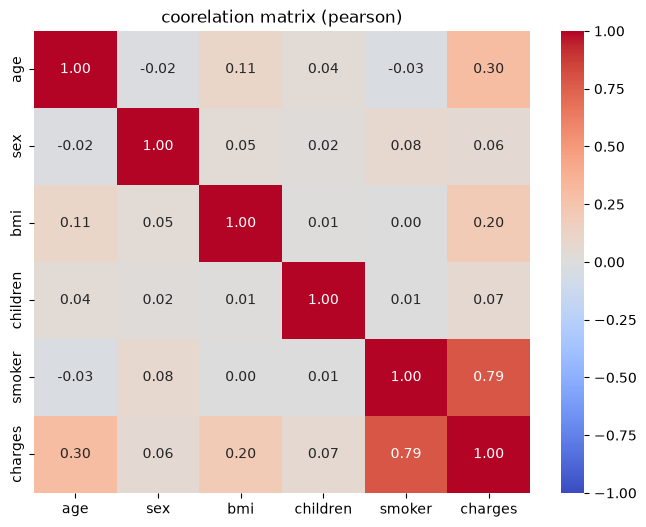

In [29]:
num_col = df_copy.select_dtypes(exclude='object').columns.to_list()
corr_matrix = df_copy[num_col].corr(method='pearson')
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix , annot=True ,cmap='coolwarm',fmt='.2f',vmin=-1 , vmax=1)
plt.title('coorelation matrix (pearson)')
plt.show()